In [1]:
import hyperopt
print(hyperopt.__version__)


0.2.7


In [2]:
from hyperopt import hp
# 간단한 두 변수 탐색 공간을 정의합니다.
search_space = {"x": hp.quniform("x", -10, 10, 1), "y": hp.quniform("y", -15, 15, 1)}


In [3]:
from hyperopt import fmin, tpe, Trials
import numpy as np
# x와 y를 사용해 최소화할 목적 함수를 정의합니다.
def objective_func(search_space):
    return search_space["x"] ** 2 - 20 * search_space["y"]
trial_val = Trials()
best_01 = fmin(objective_func, search_space, algo=tpe.suggest, max_evals=5, trials=trial_val, rstate=np.random.default_rng(seed=0))
print(best_01)
trial_val = Trials()
best_02 = fmin(objective_func, search_space, algo=tpe.suggest, max_evals=20, trials=trial_val, rstate=np.random.default_rng(seed=0))
print(best_02)
print(trial_val.results)


100%|██████████| 5/5 [00:00<00:00, 1250.02trial/s, best loss: -224.0]
{'x': -4.0, 'y': 12.0}
100%|██████████| 20/20 [00:00<00:00, 1538.32trial/s, best loss: -296.0]
{'x': 2.0, 'y': 15.0}
[{'loss': -64.0, 'status': 'ok'}, {'loss': -184.0, 'status': 'ok'}, {'loss': 56.0, 'status': 'ok'}, {'loss': -224.0, 'status': 'ok'}, {'loss': 61.0, 'status': 'ok'}, {'loss': -296.0, 'status': 'ok'}, {'loss': -40.0, 'status': 'ok'}, {'loss': 281.0, 'status': 'ok'}, {'loss': 64.0, 'status': 'ok'}, {'loss': 100.0, 'status': 'ok'}, {'loss': 60.0, 'status': 'ok'}, {'loss': -39.0, 'status': 'ok'}, {'loss': 1.0, 'status': 'ok'}, {'loss': -164.0, 'status': 'ok'}, {'loss': 21.0, 'status': 'ok'}, {'loss': -56.0, 'status': 'ok'}, {'loss': 284.0, 'status': 'ok'}, {'loss': 176.0, 'status': 'ok'}, {'loss': -171.0, 'status': 'ok'}, {'loss': 0.0, 'status': 'ok'}]


In [4]:
import pandas as pd
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
# 유방암 데이터를 학습, 검증, 테스트 세트로 나둡니다.
dataset = load_breast_cancer()
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, name="target")
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=156, stratify=y)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=156, stratify=y_train)
print(X_tr.shape, X_val.shape, X_test.shape)


(364, 30) (91, 30) (114, 30)


In [5]:
from hyperopt import STATUS_OK, hp
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier
# 교차 검증 점수를 기준으로 하이퍼파라미터를 탐색합니다.
xgb_search_space = {
    "max_depth": hp.quniform("max_depth", 3, 10, 1),
    "min_child_weight": hp.quniform("min_child_weight", 1, 10, 1),
    "learning_rate": hp.uniform("learning_rate", 0.01, 0.2),
    "colsample_bytree": hp.uniform("colsample_bytree", 0.5, 1.0),
}
def objective_func(params):
    model = XGBClassifier(n_estimators=100, max_depth=int(params["max_depth"]),
        min_child_weight=int(params["min_child_weight"]), learning_rate=params["learning_rate"],
        colsample_bytree=params["colsample_bytree"], eval_metric="logloss", random_state=156, n_jobs=1)
    score = cross_val_score(model, X_tr, y_tr, scoring="accuracy", cv=3, n_jobs=1).mean()
    return {"loss": -float(score), "status": STATUS_OK}


In [6]:
# 20회 탐색해 최적 파라미터를 고릅니다.
trials = Trials()
best = fmin(objective_func, xgb_search_space, algo=tpe.suggest, max_evals=20,
            trials=trials, rstate=np.random.default_rng(seed=0))
best["max_depth"] = int(best["max_depth"])
best["min_child_weight"] = int(best["min_child_weight"])
print(best)
print("Best CV accuracy:", -min(result["loss"] for result in trials.results))


100%|██████████| 20/20 [00:01<00:00, 11.64trial/s, best loss: -0.9587905884478164]
{'colsample_bytree': 0.9018804722261964, 'learning_rate': 0.062253093875230044, 'max_depth': 6, 'min_child_weight': 1}
Best CV accuracy: 0.9587905884478164


In [7]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score
# 학습한 모델의 분류 성능을 여러 지표로 확인합니다.
def get_clf_eval(y_true, pred, pred_proba):
    print("Confusion matrix:\n", confusion_matrix(y_true, pred))
    print(f"Accuracy: {accuracy_score(y_true, pred):.4f}")
    print(f"Precision: {precision_score(y_true, pred):.4f}")
    print(f"Recall: {recall_score(y_true, pred):.4f}")
    print(f"F1 score: {f1_score(y_true, pred):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_true, pred_proba):.4f}")


In [8]:
from xgboost import XGBClassifier
# 검증 세트로 조기 종료 시점을 결정하고 테스트 성능을 평가합니다.
xgb_wrapper = XGBClassifier(n_estimators=400, max_depth=best["max_depth"],
    min_child_weight=best["min_child_weight"], learning_rate=best["learning_rate"],
    colsample_bytree=best["colsample_bytree"], eval_metric="logloss",
    early_stopping_rounds=50, random_state=156, n_jobs=1)
xgb_wrapper.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
preds = xgb_wrapper.predict(X_test)
pred_proba = xgb_wrapper.predict_proba(X_test)[:, 1]
get_clf_eval(y_test, preds, pred_proba)
print("Best iteration:", xgb_wrapper.best_iteration)


Confusion matrix:
 [[41  1]
 [ 2 70]]
Accuracy: 0.9737
Precision: 0.9859
Recall: 0.9722
F1 score: 0.9790
ROC AUC: 0.9940
Best iteration: 284


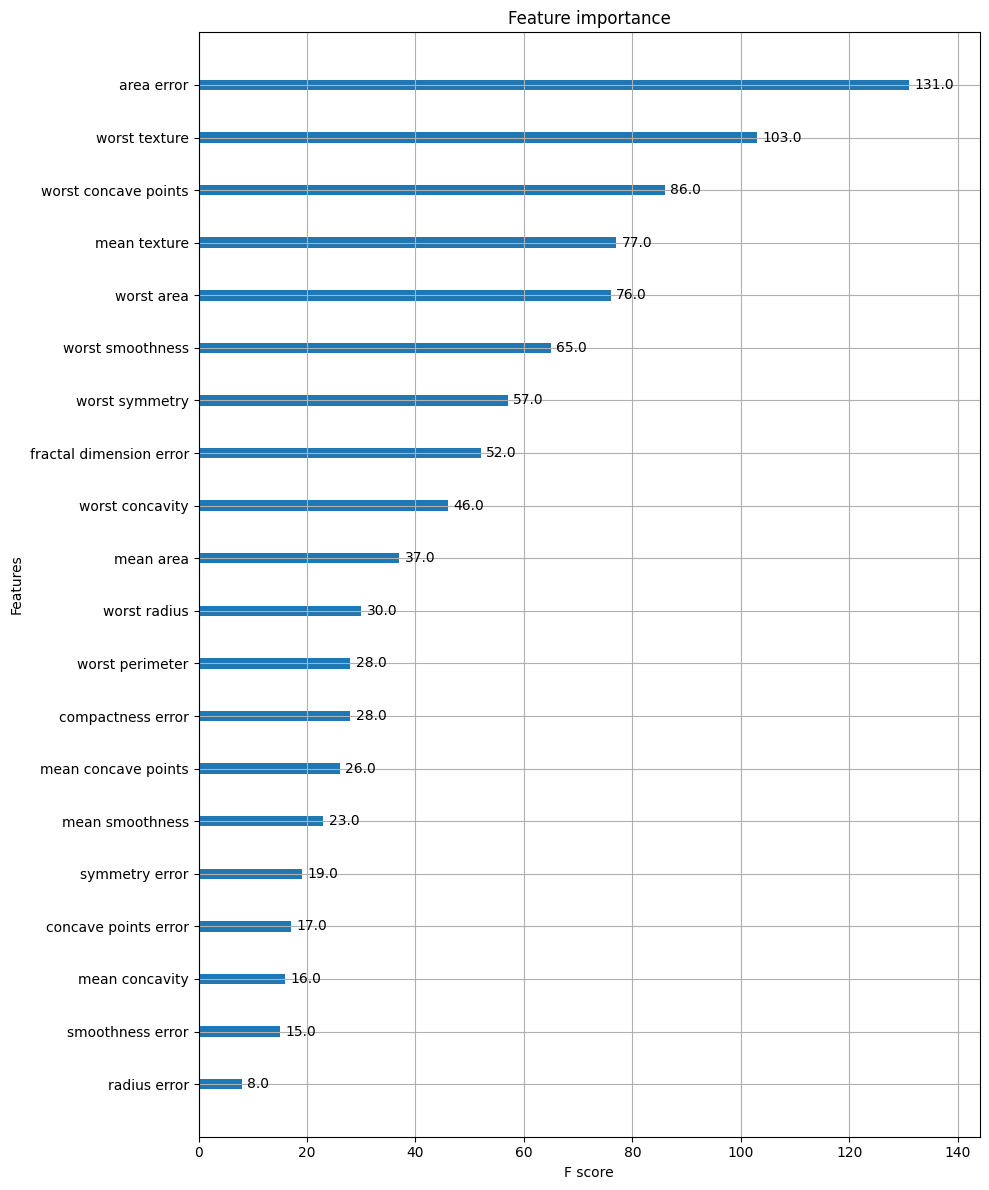

In [9]:
import matplotlib.pyplot as plt
from xgboost import plot_importance
# 최적 모델의 특성 중요도를 그립니다.
fig, ax = plt.subplots(figsize=(10, 12))
plot_importance(xgb_wrapper, ax=ax, max_num_features=20)
fig.tight_layout()
plt.show()
